# Chapter 1: Choice Under Risk and Across Time

This notebook reruns four worked examples from the chapter: insuring a risky crop (expected utility), the Arrow-Pratt risk premium, two-period saving with and without a cap, and precautionary saving. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def chord(ax, x0, y0, x1, y1, col="gold", style="solid", text=None):
    """Straight segment between two points (expected utility of a two-outcome lottery)."""
    ax.plot([x0, x1], [y0, y1], color=color(col), linestyle=style, linewidth=1.8)
    if text:
        label(ax, (x0 + x1) / 2, (y0 + y1) / 2, text, col=col, dx=4, dy=-14, va="top")


def utility_curve(ax, u, x_max, x_min=0.0, col="navy", text=None, n=300):
    """Plot u(x) on [x_min, x_max]; ``u`` is a vectorised function. Returns (x, u(x))."""
    x = np.linspace(x_min, x_max, n)
    y = u(x)
    ax.plot(x, y, color=color(col), linewidth=2.2)
    if text:
        label(ax, x[-1], y[-1], text, col=col, dx=-4, dy=-14, ha="right", va="top")
    return x, y


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


UTILITIES = {
    "sqrt": (math.sqrt, lambda u: u * u),
    "log": (math.log, math.exp),
    "linear": (lambda x: x, lambda u: u),
}


def _utility(u):
    """Accept a name in UTILITIES or a (u, u_inverse) pair."""
    if isinstance(u, str):
        return UTILITIES[u]
    return u


def expected_value(outcomes, probs):
    """Probability-weighted mean of outcomes. expected-utility-theorem: E[X] = 0.5(100) + 0.5(25) = 62.5."""
    if abs(sum(probs) - 1.0) > 1e-9:
        raise ValueError("probabilities must sum to one")
    return float(sum(p * x for p, x in zip(probs, outcomes)))


def expected_utility(probs, utils):
    """Probability-weighted utility. expected-utility-theorem: EU(A) = 0.5 sqrt(100) + 0.5 sqrt(25) = 7.5."""
    if abs(sum(probs) - 1.0) > 1e-9:
        raise ValueError("probabilities must sum to one")
    return float(sum(p * v for p, v in zip(probs, utils)))


def certainty_equivalent(lottery, u="sqrt"):
    """Sure amount with the lottery's expected utility: u(c) = E[u(X)].

    ``lottery`` is a list of (outcome, probability) pairs; ``u`` is 'sqrt', 'log',
    'linear' or a (u, u_inverse) pair. expected-utility-theorem: CE of 100/25 under
    sqrt is 56.25. arrow-pratt-risk-aversion-measure: CE of 11,000/9,000 under log is
    sqrt(99,000,000) = 9,949.87.
    """
    f, f_inv = _utility(u)
    eu = expected_utility([p for _, p in lottery], [f(x) for x, _ in lottery])
    return float(f_inv(eu))


def arrow_pratt_absolute(w, utility="log", a=None):
    """Absolute risk aversion A(w) = -u''(w)/u'(w).

    arrow-pratt-risk-aversion-measure: log utility gives A(w) = 1/w, so A(10,000) = 0.0001.
    'sqrt' gives 1/(2w); 'cara' gives the constant ``a``.
    """
    if utility == "log":
        return 1.0 / w
    if utility == "sqrt":
        return 1.0 / (2.0 * w)
    if utility == "cara":
        return float(a)
    raise ValueError(f"unknown utility {utility!r}")


def risk_premium_approx(w, stake, utility="log"):
    """Arrow-Pratt approximation pi = (1/2) A(w) Var for a fair +/- stake gamble (p = 1/2).

    arrow-pratt-risk-aversion-measure: 0.5 x 0.0001 x 1,000,000 = 50.
    """
    return 0.5 * arrow_pratt_absolute(w, utility) * stake ** 2


def risk_premium_exact(w, stake, utility="log"):
    """Exact premium w - CE for wealth w facing +/- stake with probability 1/2 each.

    arrow-pratt-risk-aversion-measure: 10,000 - sqrt(11,000 x 9,000) = 50.13.
    """
    return w - certainty_equivalent([(w + stake, 0.5), (w - stake, 0.5)], utility)


def two_period_log_consumption(y0, y1, beta, r, cap=None):
    """Two-period log-utility consumer with an optional cap on saving.

    intertemporal-choice-and-discounting: the Euler equation gives c1 = beta(1 + r) c0 and
    the budget c0 + c1/(1 + r) = y0 + y1/(1 + r). Book case y0 = 120, y1 = 100, beta = 0.96,
    r = 0.04: resources 216.1538, c0 = 110.28, c1 = 110.106 (book prints 110.10, see audit),
    saving 9.72. With cap = 5: c0 = 115, c1 = 100 + 5(1.04) = 105.20.
    Returns resources, c0, c1, saving, constrained (bool) and the unconstrained values.
    """
    R = 1.0 + r
    resources = y0 + y1 / R
    c0_free = resources / (1.0 + beta)
    c1_free = beta * R * c0_free
    s_free = y0 - c0_free
    constrained = cap is not None and s_free > cap
    if constrained:
        s = float(cap)
        c0, c1 = y0 - s, y1 + s * R
    else:
        s, c0, c1 = s_free, c0_free, c1_free
    return {"resources": resources, "c0": c0, "c1": c1, "saving": s, "constrained": constrained,
            "c0_free": c0_free, "c1_free": c1_free, "saving_free": s_free, "euler_ratio": beta * R}


def precautionary_saving(spread, utility="log", base=100.0):
    """Optimal saving s with resources ``base`` today and base +/- spread tomorrow (p = 1/2), r = 0, no discounting.

    prudence-and-precautionary-saving. Log utility: the Euler equation
    1/(100 - s) = (1/2)/(50 + s) + (1/2)/(150 + s) reduces to s^2 + base s - spread^2/2 = 0,
    so s = (-base + sqrt(base^2 + 2 spread^2)) / 2; spread 50 gives (-100 + sqrt(15,000))/2 = 11.24.
    Quadratic utility u(c) = 200c - c^2/2 has linear marginal utility, so s = 0 for any spread.
    Returns a dict with s, c0, c1_low, c1_high.
    """
    if utility == "log":
        s = (-base + math.sqrt(base * base + 2.0 * spread * spread)) / 2.0
    elif utility == "quadratic":
        s = 0.0
    else:
        raise ValueError(f"unknown utility {utility!r}")
    return {"s": s, "c0": base - s, "c1_low": base - spread + s, "c1_high": base + spread + s}


def precautionary_marginal_utilities(s, spread, utility="log", base=100.0):
    """Current and expected future marginal utility at saving s (the two sides of the Euler equation)."""
    if utility == "log":
        now = 1.0 / (base - s)
        future = 0.5 / (base - spread + s) + 0.5 / (base + spread + s)
    elif utility == "quadratic":
        now = 200.0 - (base - s)
        future = 0.5 * (200.0 - (base - spread + s)) + 0.5 * (200.0 - (base + spread + s))
    else:
        raise ValueError(f"unknown utility {utility!r}")
    return now, future


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(expected_value=expected_value, expected_utility=expected_utility, certainty_equivalent=certainty_equivalent, arrow_pratt_absolute=arrow_pratt_absolute, risk_premium_approx=risk_premium_approx, risk_premium_exact=risk_premium_exact, two_period_log_consumption=two_period_log_consumption, precautionary_saving=precautionary_saving, precautionary_marginal_utilities=precautionary_marginal_utilities)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'expected-utility-theorem': {'high': 100,
                              'low': 25,
                              'p': 0.5,
                              'insured': 58,
                              'expected_income': 62.5,
                              'eu_A': 7.5,
                              'ce': 56.25,
                              'risk_premium': 6.25,
                              'eu_B': 7.616,
                              'sacrifice': 4.5},
 'arrow-pratt-risk-aversion-measure': {'wealth': 10000,
                                       'stake': 1000,
                                       'A': 0.0001,
                                       'variance': 1000000,
                                       'approx': 50.0,
                                       'ce': 9949.87,
                                       'exact': 50.13,
                                       'wealth_2': 20000,
                                       'A_2': 5e-05,
                                       'approx_2': 25.0,
                                       'exact_2': 25.02},
 'intertemporal-choice-and-discounting': {'y0': 120,
                                          'y1': 100,
                                          'beta': 0.96,
                                          'r': 0.04,
                                          'euler_ratio': 0.9984,
                                          'resources': 216.1538,
                                          'c0': 110.28,
                                          'saving': 9.72,
                                          'c1_printed_as': 110.1,
                                          'c1_exact_2dp': 110.11,
                                          'r0': {'c0': 112.24,
                                                 'c1': 107.76,
                                                 'saving': 7.76,
                                                 'resources': 220},
                                          'cap': 5,
                                          'cap_c0': 115,
                                          'cap_c1': 105.2},
 'prudence-and-precautionary-saving': {'base': 100,
                                       'spread': 50,
                                       's': 11.24,
                                       'c0': 88.76,
                                       'c1_low': 61.24,
                                       'c1_high': 161.24,
                                       's_quadratic': 0.0},
 'constructed': {'expected-utility-theorem': {'low': [9, 16, 36], 'insured': [54, 62]},
                 'arrow-pratt-risk-aversion-measure': {'wealth': [5000, 40000], 'stake': [500]},
                 'intertemporal-choice-and-discounting': {'r': [0.02, 0.08]},
                 'prudence-and-precautionary-saving': {'spread': [25, 75]}}}


def cents(x):
    """Dollars to the cent, or to a tenth of a cent when the cent figure would round a half."""
    return money(x) if abs(x * 100 - round(x * 100)) < 1e-9 else f"${x:,.3f}"


def gap(x):
    """Approximation error; under half a cent is named, not shown as $0.00."""
    return money(x) if x >= 0.005 else "under $0.01"


def small(x):
    """0.0001 style: up to 6 decimals, trailing zeros removed."""
    return f"{x:.6f}".rstrip("0").rstrip(".")


def insure_picture(low=25, insured=58):
    high = BV["expected-utility-theorem"]["high"]
    lottery = [(high, 0.5), (low, 0.5)]
    ex = choice.expected_value([high, low], [0.5, 0.5])
    eu_a = choice.expected_utility([0.5, 0.5], [math.sqrt(high), math.sqrt(low)])
    ce = choice.certainty_equivalent(lottery, "sqrt")
    premium = ex - ce
    eu_b = math.sqrt(insured)
    pick_b = eu_b > eu_a
    fig, ax = new_figure()
    utility_curve(ax, np.sqrt, 110, text="u(x) = sqrt(x)")
    chord(ax, low, math.sqrt(low), high, math.sqrt(high))
    ax.plot([ce, ex], [eu_a, eu_a], color=PALETTE["terracotta"], linewidth=4, solid_capstyle="butt")
    mark(ax, ex, eu_a, f"E[X] = {num(ex)}", col="gold", dx=8, dy=8)
    mark(ax, ce, eu_a, f"CE = {num(ce)}", col="navy", dx=-8, dy=8, ha="right")
    mark(ax, insured, eu_b, f"B: sqrt({insured}) = {num(eu_b, 3)}", col="teal", dx=10, dy=-40, va="top")
    ax.text(0.97, 0.06, f"red bar: risk premium E[X] - CE = {num(premium)}", transform=ax.transAxes, ha="right",
            va="bottom", fontsize=10.5, color=PALETTE["terracotta"])
    ax.set_xlim(0, 112)
    ax.set_ylim(0, 11.5)
    ax.set_xlabel("Final income ($ thousand)")
    ax.set_ylabel("Utility")
    verdict = ("B gives higher expected utility, so the decision maker insures" if pick_b
               else "A gives higher expected utility, so the decision maker stays uninsured")
    if insured == ex:
        trade = (f"Insurance pays exactly A's expected income of {num(ex)} thousand, so no expected income is "
                 f"given up.")
    elif insured < ex:
        trade = (f"Insurance gives up {num(ex - insured)} thousand of expected income, "
                 f"{'less' if pick_b else 'more'} than the {num(premium)} thousand risk premium.")
    else:
        trade = (f"Insurance pays {num(insured - ex)} thousand more than A's expected income, so no expected "
                 f"income is given up.")
    metrics = {"Expected income E[X] ($000)": num(ex), "EU(A)": num(eu_a, 3), "Certainty equivalent ($000)": num(ce),
               "Risk premium ($000)": num(premium), "EU(B)": num(eu_b, 3),
               "Choice": "Insure (B)" if pick_b else "Stay uninsured (A)"}
    interp = (f"EU(A) = 0.5 x sqrt(100) + 0.5 x sqrt({low}) = 0.5 x 10 + 0.5 x {num(math.sqrt(low), 0)} = "
              f"{num(eu_a, 3)}. The certainty equivalent solves sqrt(c) = {num(eu_a, 3)}, so c = {num(ce)}, and the "
              f"risk premium is {num(ex)} - {num(ce)} = {num(premium)}. EU(B) = sqrt({insured}) = {num(eu_b, 3)}. "
              f"{verdict}. {trade}")
    steps = [f"E[X] = 0.5 x 100 + 0.5 x {low} = {num(ex)}",
             f"EU(A) = 0.5 x 10 + 0.5 x {num(math.sqrt(low), 0)} = {num(eu_a, 3)}",
             f"CE = {num(eu_a, 3)} x {num(eu_a, 3)} = {num(ce)}",
             f"Risk premium = {num(ex)} - {num(ce)} = {num(premium)}",
             f"EU(B) = sqrt({insured}) = {num(eu_b, 3)}, {'above' if pick_b else 'below'} EU(A) = {num(eu_a, 3)}"]
    alt = (f"The square-root utility curve with a chord from bad-year income {low} to 100. On the chord at expected "
           f"income {num(ex)} the utility is {num(eu_a, 3)}; the curve reaches that utility at the certainty "
           f"equivalent {num(ce)}. The insured point at {insured} has utility {num(eu_b, 3)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def premium_picture(wealth=10_000, stake=1_000):
    a = choice.arrow_pratt_absolute(wealth, "log")
    var = stake ** 2
    approx = choice.risk_premium_approx(wealth, stake, "log")
    exact = choice.risk_premium_exact(wealth, stake, "log")
    ce = wealth - exact
    ws = np.linspace(4_000, 42_000, 200)
    fig, ax = new_figure()
    ax.plot(ws, [choice.risk_premium_exact(w, stake) for w in ws], color=PALETTE["teal"], linewidth=2.2)
    ax.plot(ws, [choice.risk_premium_approx(w, stake) for w in ws], color=PALETTE["gold"], linewidth=1.8,
            linestyle="dashed")
    top = choice.risk_premium_exact(4_000, stake)
    ax.lines[0].set_label("exact premium")
    ax.lines[1].set_label("approximation (1/2) A(w) Var")
    ax.legend(loc="upper right", frameon=False)
    right = wealth > 30_000
    mark(ax, wealth, exact, f"{money(exact)} at {money(wealth, 0)}", col="ink", dx=-8 if right else 8, dy=10,
         ha="right" if right else "left")
    ax.set_xlim(3_000, 43_000)
    ax.set_ylim(0, top * 1.12)
    ax.set_xlabel("Initial wealth ($)")
    ax.set_ylabel(tex_safe(f"Risk premium for +/- {money(stake, 0)} ($)"))
    metrics = {"A(w) = 1/w": small(a), "Variance": num(var, 0), "Approximate premium": cents(approx),
               "Certainty equivalent": money(ce), "Exact premium": money(exact),
               "Approximation error": gap(exact - approx)}
    interp = (f"A(w) = 1/{num(wealth, 0)} = {small(a)}, so the approximation is 0.5 x {small(a)} x {num(var, 0)} = "
              f"{cents(approx)}. The exact certainty equivalent is sqrt({num(wealth + stake, 0)} x "
              f"{num(wealth - stake, 0)}) = {money(ce)}, so the exact premium is {money(wealth, 0)} - {money(ce)} = "
              f"{money(exact)}. The approximation misses by {gap(exact - approx)}.")
    steps = [f"A(w) = 1 / {num(wealth, 0)} = {small(a)}",
             f"Var = {num(stake, 0)} x {num(stake, 0)} = {num(var, 0)}",
             f"pi approx = 0.5 x {small(a)} x {num(var, 0)} = {cents(approx)}",
             f"CE = sqrt({num(wealth + stake, 0)} x {num(wealth - stake, 0)}) = {money(ce)}",
             f"Exact premium = {num(wealth, 0)} - {num(ce)} = {money(exact)}"]
    alt = (f"Risk premium against wealth for a gamble of plus or minus {money(stake, 0)}: the exact premium and the "
           f"approximation both fall as wealth rises. At {money(wealth, 0)} the exact premium is {money(exact)} and "
           f"the approximation {cents(approx)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def saving_picture(r=0.04, cap="none"):
    bv = BV["intertemporal-choice-and-discounting"]
    y0, y1, beta = bv["y0"], bv["y1"], bv["beta"]
    cap_value = None if cap == "none" else float(cap)
    res = choice.two_period_log_consumption(y0, y1, beta, r, cap_value)
    R = 1 + r
    fig, ax = new_figure()
    c0s = np.linspace(80, 150, 200)
    ax.plot(c0s, (res["resources"] - c0s) * R, color=PALETTE["ink"], linewidth=1.8)
    u = math.log(res["c0"]) + beta * math.log(res["c1"])
    cc = np.linspace(85, 150, 200)
    ax.plot(cc, np.exp((u - np.log(cc)) / beta), color=PALETTE["teal"], linewidth=1.8)
    label(ax, 145, math.exp((u - math.log(145)) / beta), "indifference curve", col="teal", dx=-4, dy=6, ha="right")
    label(ax, 146, (res["resources"] - 146) * R, f"budget at r = {num(100 * r, 0)}%", col="ink", dx=-6, dy=6, ha="right")
    mark(ax, y0, y1, "income (120, 100)", col="gold", dx=8, dy=-14, va="top")
    if cap_value is not None:
        vline(ax, y0 - cap_value, f"cap: c0 at least {num(y0 - cap_value, 0)}", col="terracotta", ha="left",
              y_frac=0.97)
    mark(ax, res["c0"], res["c1"], f"chosen ({num(res['c0'])}, {num(res['c1'])})", col="navy", dx=-8, dy=8, ha="right")
    ax.set_xlim(80, 150)
    ax.set_ylim(70, 140)
    ax.set_xlabel("Consumption today c0 ($ thousand)")
    ax.set_ylabel("Consumption next period c1 ($ thousand)")
    metrics = {"Lifetime resources": num(res["resources"], 4), "c0 today": num(res["c0"]), "c1 next period": num(res["c1"]),
               "Saving": num(res["saving"]), "beta(1 + r)": num(res["euler_ratio"], 4),
               "Saving cap": "binds" if res["constrained"] else ("none" if cap_value is None else "does not bind")}
    if res["constrained"]:
        interp = (f"Unconstrained, the consumer would save {num(res['saving_free'])}, more than the cap of "
                  f"{num(cap_value, 0)}. So c0 = 120 - {num(cap_value, 0)} = {num(res['c0'])} and c1 = 100 + "
                  f"{num(cap_value, 0)} x {num(R, 2)} = {num(res['c1'])}. The Euler condition no longer holds: the "
                  f"path reflects the constraint, not impatience.")
        steps = [f"Resources = 120 + 100 / {num(R, 2)} = {num(res['resources'], 4)}",
                 f"Free choice: c0 = {num(res['resources'], 4)} / 1.96 = {num(res['c0_free'], 4)}, saving "
                 f"{num(res['saving_free'])}",
                 f"Saving {num(res['saving_free'])} exceeds the cap {num(cap_value, 0)}, so saving = {num(cap_value, 0)}",
                 f"c0 = 120 - {num(cap_value, 0)} = {num(res['c0'])}",
                 f"c1 = 100 + {num(cap_value, 0)} x {num(R, 2)} = {num(res['c1'])}"]
    else:
        interp = (f"beta(1 + r) = 0.96 x {num(R, 2)} = {num(res['euler_ratio'], 4)}, so c1 = "
                  f"{num(res['euler_ratio'], 4)} c0. Resources are 120 + 100 / {num(R, 2)} = "
                  f"{num(res['resources'], 4)}, so c0 = {num(res['resources'], 4)} / (1 + 0.96) = "
                  f"{num(res['c0'], 4)} and c1 = {num(res['euler_ratio'], 4)} x {num(res['c0'], 4)} = "
                  f"{num(res['c1'])}. Saving is 120 - {num(res['c0'])} = {num(res['saving'])}"
                  + (f", within the cap of {num(cap_value, 0)}." if cap_value is not None else ".")
                  + (" The book prints next-period consumption as 110.10 and the grown saving as about 10.10; the "
                     "exact values are 110.106 and 10.106, which round to 110.11 and 10.11."
                     if abs(r - 0.04) < 1e-12 else ""))
        steps = [f"beta(1 + r) = 0.96 x {num(R, 2)} = {num(res['euler_ratio'], 4)}",
                 f"Resources = 120 + 100 / {num(R, 2)} = {num(res['resources'], 4)}",
                 f"c0 = {num(res['resources'], 4)} / 1.96 = {num(res['c0'], 4)}",
                 f"c1 = {num(res['euler_ratio'], 4)} x {num(res['c0'], 4)} = {num(res['c1'])}",
                 f"Saving = 120 - {num(res['c0'], 4)} = {num(res['saving'])}"]
    alt = (f"Two-period budget line at an interest rate of {num(100 * r, 0)} percent through the income point "
           f"(120, 100). The chosen point is ({num(res['c0'])}, {num(res['c1'])})"
           + (", on the saving cap line." if res["constrained"] else ", where the indifference curve touches the budget line."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def prudence_picture(spread=50, util="log"):
    res = choice.precautionary_saving(spread, util)
    s = res["s"]
    grid = np.linspace(-10, 40, 300)
    now, fut = zip(*[choice.precautionary_marginal_utilities(x, spread, util) for x in grid])
    fig, ax = new_figure()
    ax.plot(grid, now, color=PALETTE["navy"], linewidth=2.2)
    ax.plot(grid, fut, color=PALETTE["teal"], linewidth=2.2)
    ax.lines[0].set_label("u'(c0) today")
    ax.lines[1].set_label("expected u'(c1) next period")
    ax.legend(loc="upper left", frameon=False)
    y_s = choice.precautionary_marginal_utilities(s, spread, util)[0]
    mark(ax, s, y_s, f"s = {num(s)}", col="ink", dx=-10, dy=10, ha="right")
    ax.set_xlim(-10, 40)
    lo, hi = min(min(now), min(fut)), max(max(now), max(fut))
    ax.set_ylim(lo - 0.05 * (hi - lo), hi + 0.08 * (hi - lo))
    ax.set_xlabel("Saving s carried forward")
    ax.set_ylabel("Marginal utility")
    metrics = {"Optimal saving s": num(s), "c0 today": num(res["c0"]), "c1 in the low state": num(res["c1_low"]),
               "c1 in the high state": num(res["c1_high"]), "Future income": f"{num(100 - spread, 0)} or {num(100 + spread, 0)}"
               if spread else "100 for certain"}
    if util == "log":
        root = math.sqrt(10_000 + 2 * spread ** 2)
        calc = (f"s = (-100 + sqrt(10,000 + 2 x {spread} x {spread})) / 2 = (-100 + {num(root, 3)}) / 2 = {num(s)}")
        why = ("Log utility has u''' = 2/c^3 > 0, so risk raises expected future marginal utility and the consumer "
               "saves." if spread else "With no risk the two periods are alike and the consumer saves nothing.")
        steps = [f"Future income is {num(100 - spread, 0)} or {num(100 + spread, 0)} with probability one half each"
                 if spread else "Future income is 100 for certain",
                 f"The Euler equation reduces to s^2 + 100 s - {num(spread * spread / 2, 0 if spread % 2 == 0 else 1)} = 0",
                 f"sqrt(10,000 + {num(2 * spread * spread, 0)}) = {num(root, 3)}",
                 f"s = (-100 + {num(root, 3)}) / 2 = {num(s)}",
                 f"c0 = 100 - {num(s)} = {num(res['c0'])}; c1 = {num(res['c1_low'])} or {num(res['c1_high'])}"]
    else:
        calc = (f"u'(c) = 200 - c, so expected future marginal utility is 0.5 x (200 - ({num(100 - spread, 0)} + s)) + "
                f"0.5 x (200 - ({num(100 + spread, 0)} + s)) = 100 - s, and 100 + s = 100 - s gives s = 0")
        why = "Quadratic utility has u''' = 0, so the spread leaves expected marginal utility unchanged: no precautionary saving."
        steps = ["u'(c) = 200 - c, a straight line, so u''' = 0",
                 f"Expected future u' = 0.5 x (100 - s + {spread}) + 0.5 x (100 - s - {spread}) = 100 - s",
                 "Current u' = 200 - (100 - s) = 100 + s",
                 "100 + s = 100 - s gives s = 0.00"]
    interp = f"{calc}. {why}"
    alt = (f"Current and expected future marginal utility against saving. The curves cross at s = {num(s)}, with "
           f"future income {('100 for certain' if not spread else f'{100 - spread} or {100 + spread}')} and "
           f"{'log' if util == 'log' else 'quadratic'} utility.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Expected-utility theorem: insure the crop or bear the risk

Income $x$ is in thousands of dollars and $u(x)=\sqrt{x}$. Lottery A pays 100 or 25 with probability one half each; contract B pays 58 for certain.

$$EU(A)=\tfrac12\sqrt{100}+\tfrac12\sqrt{25}=7.5$$

The certainty equivalent solves $u(c)=E[u(X)]$, and $EU(B)=\sqrt{58}\approx7.616$.

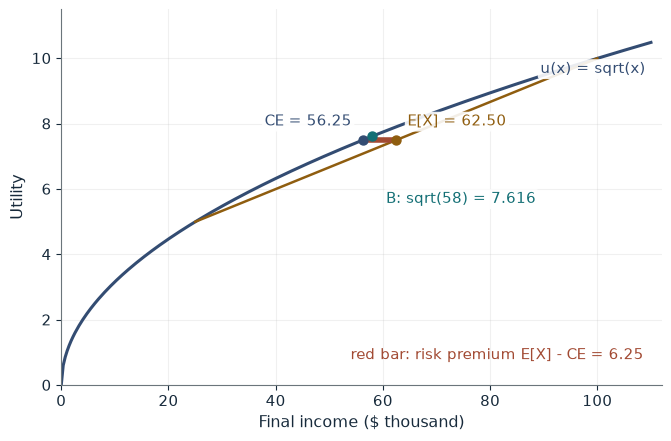

Expected income E[X] ($000)  62.50
EU(A)                        7.500
Certainty equivalent ($000)  56.25
Risk premium ($000)          6.25
EU(B)                        7.616
Choice                       Insure (B)

Worked steps:
  1. E[X] = 0.5 x 100 + 0.5 x 25 = 62.50
  2. EU(A) = 0.5 x 10 + 0.5 x 5 = 7.500
  3. CE = 7.500 x 7.500 = 56.25
  4. Risk premium = 62.50 - 56.25 = 6.25
  5. EU(B) = sqrt(58) = 7.616, above EU(A) = 7.500

EU(A) = 0.5 x sqrt(100) + 0.5 x sqrt(25) = 0.5 x 10 + 0.5 x 5 = 7.500. The certainty equivalent solves sqrt(c) = 7.500, so c = 56.25, and the risk premium is 62.50 - 56.25 = 6.25. EU(B) = sqrt(58) = 7.616. B gives higher expected utility, so the decision maker insures. Insurance gives up 4.50 thousand of expected income, less than the 6.25 thousand risk premium.


In [2]:
show(insure_picture(low=25, insured=58))

Change one input, `low`, and hold the others at the book's values:

In [3]:
sweep(insure_picture, 'low', [9, 16, 25, 36], {'insured': 58}, ['EU(A)', 'Certainty equivalent ($000)', 'Risk premium ($000)', 'Choice'])

low | EU(A) | Certainty equivalent ($000) | Risk premium ($000) | Choice
9 | 6.500 | 42.25 | 12.25 | Insure (B)
16 | 7.000 | 49.00 | 9.00 | Insure (B)
25 | 7.500 | 56.25 | 6.25 | Insure (B)
36 | 8.000 | 64.00 | 4.00 | Stay uninsured (A)


B wins because its sure 58 is above the certainty equivalent 56.25: the decision maker gives up 4.50 of expected income, less than the 6.25 risk premium. Once bad-year income reaches 36 the certainty equivalent is 64 and the uninsured lottery wins.

## 2. Arrow-Pratt measure: same gamble, richer person

Wealth is \$10,000, utility is $\ln w$ and the gamble is plus or minus \$1,000 with probability one half.

$$A(w)=\frac{1}{w}, \qquad \pi\approx\frac{1}{2}A(w)\operatorname{Var}(\varepsilon)$$

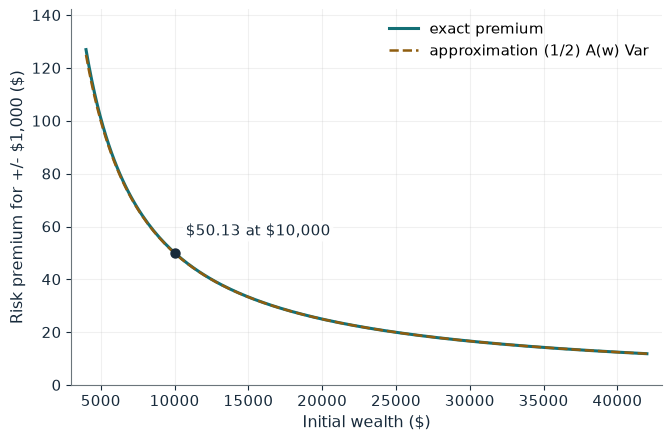

A(w) = 1/w            0.0001
Variance              1,000,000
Approximate premium   $50.00
Certainty equivalent  $9,949.87
Exact premium         $50.13
Approximation error   $0.13

Worked steps:
  1. A(w) = 1 / 10,000 = 0.0001
  2. Var = 1,000 x 1,000 = 1,000,000
  3. pi approx = 0.5 x 0.0001 x 1,000,000 = $50.00
  4. CE = sqrt(11,000 x 9,000) = $9,949.87
  5. Exact premium = 10,000 - 9,949.87 = $50.13

A(w) = 1/10,000 = 0.0001, so the approximation is 0.5 x 0.0001 x 1,000,000 = $50.00. The exact certainty equivalent is sqrt(11,000 x 9,000) = $9,949.87, so the exact premium is $10,000 - $9,949.87 = $50.13. The approximation misses by $0.13.


In [4]:
show(premium_picture(wealth=10_000, stake=1_000))

Change one input, `wealth`, and hold the others at the book's values:

In [5]:
sweep(premium_picture, 'wealth', [5000, 10000, 20000, 40000], {'stake': 1000}, ['A(w) = 1/w', 'Approximate premium', 'Exact premium'])

wealth | A(w) = 1/w | Approximate premium | Exact premium
5000 | 0.0002 | $100.00 | $101.02
10000 | 0.0001 | $50.00 | $50.13
20000 | 0.00005 | $25.00 | $25.02
40000 | 0.000025 | $12.50 | $12.50


The approximation gives \$50.00 against an exact \$50.13. Doubling wealth halves absolute risk aversion and roughly halves the premium for the same dollar gamble.

## 3. Intertemporal choice: saving when the interest rate moves

Income is 120 today and 100 next period, $\beta=0.96$ and utility is $\ln c_0+\beta\ln c_1$. At $r=0.04$ the Euler equation gives $c_1=0.9984c_0$ and the budget is

$$c_0+\frac{c_1}{1.04}=216.1538$$

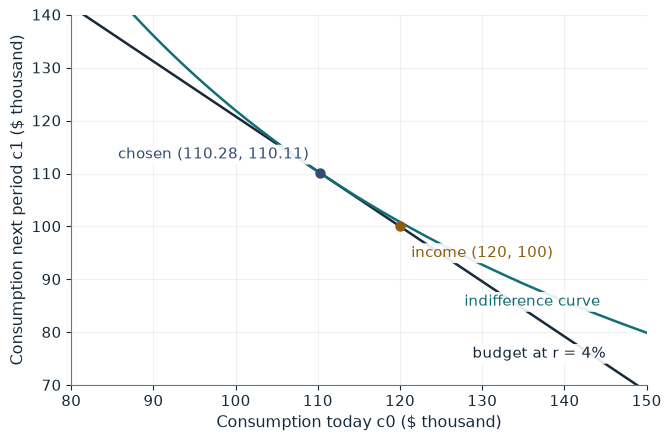

Lifetime resources  216.1538
c0 today            110.28
c1 next period      110.11
Saving              9.72
beta(1 + r)         0.9984
Saving cap          none

Worked steps:
  1. beta(1 + r) = 0.96 x 1.04 = 0.9984
  2. Resources = 120 + 100 / 1.04 = 216.1538
  3. c0 = 216.1538 / 1.96 = 110.2826
  4. c1 = 0.9984 x 110.2826 = 110.11
  5. Saving = 120 - 110.2826 = 9.72

beta(1 + r) = 0.96 x 1.04 = 0.9984, so c1 = 0.9984 c0. Resources are 120 + 100 / 1.04 = 216.1538, so c0 = 216.1538 / (1 + 0.96) = 110.2826 and c1 = 0.9984 x 110.2826 = 110.11. Saving is 120 - 110.28 = 9.72. The book prints next-period consumption as 110.10 and the grown saving as about 10.10; the exact values are 110.106 and 10.106, which round to 110.11 and 10.11.


In [6]:
show(saving_picture(r=0.04, cap='none'))

Change one input, `r`, and hold the others at the book's values:

In [7]:
sweep(saving_picture, 'r', [0.0, 0.02, 0.04, 0.08], {'cap': 'none'}, ['c0 today', 'c1 next period', 'Saving'])

r | c0 today | c1 next period | Saving
0.0 | 112.24 | 107.76 | 7.76
0.02 | 111.24 | 108.93 | 8.76
0.04 | 110.28 | 110.11 | 9.72
0.08 | 108.47 | 112.46 | 11.53


At 4 percent the consumer saves 9.72 and consumes 110.11 next period (0.9984 x 110.2826 = 110.106; the book prints 110.10). At a zero rate saving falls to 7.76. With a cap of 5 (`cap='5'`) consumption is 115 today and 105.20 next period: the path reflects the constraint, not impatience.

## 4. Prudence and precautionary saving

Resources are 100 today; next period income is 100 plus or minus the spread, with no interest and no discounting. With log utility the Euler equation is

$$\frac{1}{100-s}=\frac{1}{2}\frac{1}{50+s}+\frac{1}{2}\frac{1}{150+s}, \qquad s=\frac{-100+\sqrt{15{,}000}}{2}\approx 11.24$$

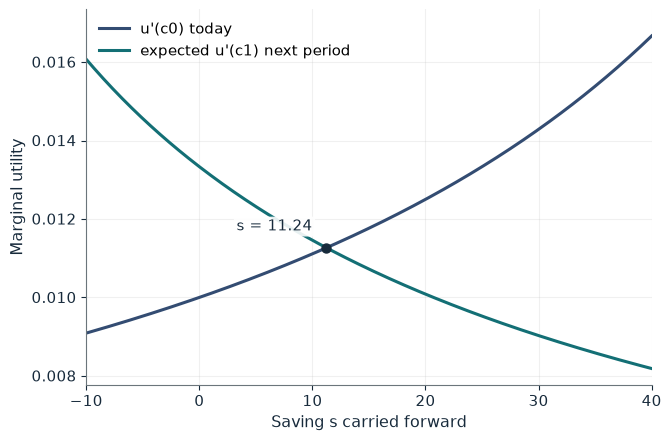

Optimal saving s      11.24
c0 today              88.76
c1 in the low state   61.24
c1 in the high state  161.24
Future income         50 or 150

Worked steps:
  1. Future income is 50 or 150 with probability one half each
  2. The Euler equation reduces to s^2 + 100 s - 1,250 = 0
  3. sqrt(10,000 + 5,000) = 122.474
  4. s = (-100 + 122.474) / 2 = 11.24
  5. c0 = 100 - 11.24 = 88.76; c1 = 61.24 or 161.24

s = (-100 + sqrt(10,000 + 2 x 50 x 50)) / 2 = (-100 + 122.474) / 2 = 11.24. Log utility has u''' = 2/c^3 > 0, so risk raises expected future marginal utility and the consumer saves.


In [8]:
show(prudence_picture(spread=50, util='log'))

Change one input, `spread`, and hold the others at the book's values:

In [9]:
sweep(prudence_picture, 'spread', [0, 25, 50, 75], {'util': 'log'}, ['Optimal saving s', 'c0 today'])

spread | Optimal saving s | c0 today
0 | 0.00 | 100.00
25 | 3.03 | 96.97
50 | 11.24 | 88.76
75 | 22.89 | 77.11


Log utility has a positive third derivative, so risk raises expected future marginal utility and the consumer saves 11.24. With quadratic utility $u(c)=200c-c^2/2$ (`util='quadratic'`) marginal utility is linear and saving stays at zero.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

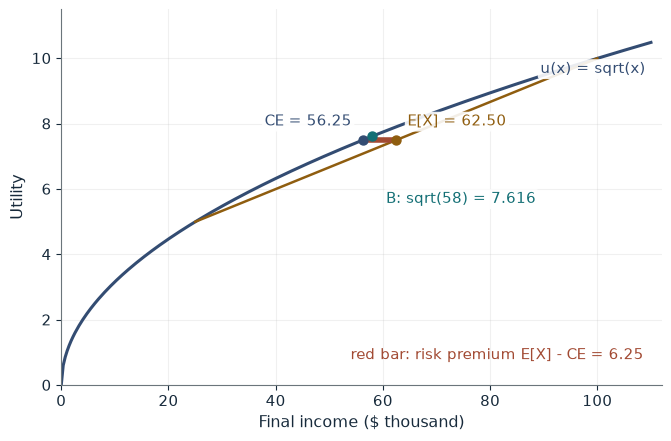

Expected income E[X] ($000)  62.50
EU(A)                        7.500
Certainty equivalent ($000)  56.25
Risk premium ($000)          6.25
EU(B)                        7.616
Choice                       Insure (B)

Worked steps:
  1. E[X] = 0.5 x 100 + 0.5 x 25 = 62.50
  2. EU(A) = 0.5 x 10 + 0.5 x 5 = 7.500
  3. CE = 7.500 x 7.500 = 56.25
  4. Risk premium = 62.50 - 56.25 = 6.25
  5. EU(B) = sqrt(58) = 7.616, above EU(A) = 7.500

EU(A) = 0.5 x sqrt(100) + 0.5 x sqrt(25) = 0.5 x 10 + 0.5 x 5 = 7.500. The certainty equivalent solves sqrt(c) = 7.500, so c = 56.25, and the risk premium is 62.50 - 56.25 = 6.25. EU(B) = sqrt(58) = 7.616. B gives higher expected utility, so the decision maker insures. Insurance gives up 4.50 thousand of expected income, less than the 6.25 thousand risk premium.


In [10]:
show(insure_picture(low=25, insured=58))

## Practice

**1.** With bad-year income 36 and insured income 58, which contract is chosen, and what is the risk premium?

<details><summary>Answer</summary>

EU(A) = 0.5 x 10 + 0.5 x 6 = 8, so CE = 64 and E[X] = 68; the premium is 4. Since sqrt(58) = 7.616 < 8, the uninsured lottery A is chosen.

</details>

**2.** At wealth \$40,000 and a \$1,000 gamble, what is the approximate risk premium?

<details><summary>Answer</summary>

A = 1/40,000 = 0.000025, so pi = 0.5 x 0.000025 x 1,000,000 = \$12.50.

</details>

**3.** With log utility and a spread of 25 (future income 75 or 125), how much does the consumer save?

<details><summary>Answer</summary>

s^2 + 100 s - 312.5 = 0, so s = (-100 + sqrt(11,250)) / 2 = (-100 + 106.066) / 2 = 3.03.

</details>